# Which criterion can stop value iteration?

For one MDP, compute $V_{k+1}=TV_k$ and compare when the Bellman residual, residual span and lower/upper envelope first meet the same absolute precision $\varepsilon$. No catalogue solver is called.

Each criterion certifies a particular returned vector. Compare their value errors as well as stopping iterations; this experiment does not measure policy quality or runtime.

In [1]:
from importlib import import_module

import matplotlib.pyplot as plt
import numpy as np

MODEL_NAME = "cliff"
STATE_DIM = 500
ACTION_DIM = 5
SEED = 7
DISCOUNT = 0.99
PRECISION = 1e-3
REFERENCE_PRECISION = 1e-9
MAX_ITERATIONS = 10_000

assert 0 < DISCOUNT < 1
assert 0 < REFERENCE_PRECISION < PRECISION
assert MAX_ITERATIONS > 0

Model = import_module(f"mdpforge.models.{MODEL_NAME}").Model
model = Model(state_dim=STATE_DIM)

# Rebuild this small experimental instance with a fixed seed, without a cache.
rng_state = np.random.get_state()
try:
    np.random.seed(SEED)
    model.create_model(check_transition=True, cache="off")
finally:
    np.random.set_state(rng_state)

print(f"{model.name} | states={model.state_dim}, actions={model.action_dim}")
print(f"discount={DISCOUNT}, precision={PRECISION:g}, seed={SEED}")

432_4_cliff | states=432, actions=4
discount=0.99, precision=0.001, seed=7


## Three criteria and their returned values

Let $r_k=TV_k-V_k$, $m_k=\min_s r_k(s)$ and $M_k=\max_s r_k(s)$. For stochastic transitions and $0<\gamma<1$, the componentwise bounds are $V_k+m_k/(1-\gamma)\leq V^*\leq V_k+M_k/(1-\gamma)$.

- **Bellman residual:** $B_R(k)=\|r_k\|_\infty/(1-\gamma)$ bounds $\|V_k-V^*\|_\infty$.
- **Span:** $B_S(k)=(M_k-m_k)/(2(1-\gamma))$ certifies the midpoint $W_k=V_k+(m_k+M_k)/(2(1-\gamma))$. Span alone ignores constant shifts and does not certify the absolute error of $V_k$.
- **Envelope:** initialize $L_0=\min R/(1-\gamma)$ and $U_0=\max R/(1-\gamma)$, then apply $L_{k+1}=TL_k$ and $U_{k+1}=TU_k$. Thus $L_k\leq V^*\leq U_k$, and $B_E(k)=\|U_k-L_k\|_\infty/2$ certifies $E_k=(L_k+U_k)/2$.

The envelope uses two extra full Bellman updates per iteration, without aggregation or span tightening. Constant initial bounds give $U_k-L_k=\gamma^k(U_0-L_0)$ in exact arithmetic, so this envelope can be conservative.

In [2]:
rewards = model.reward_matrix
transitions = model.transition_matrix


def bellman(value):
    """Apply the optimal Bellman map explicitly, one action at a time."""
    q_values = np.empty((model.state_dim, model.action_dim))
    for action, transition in enumerate(transitions):
        q_values[:, action] = rewards[:, action] + DISCOUNT * (transition @ value)
    return q_values.max(axis=1)


value = np.zeros(model.state_dim)
lower = np.full(model.state_dim, rewards.min() / (1 - DISCOUNT))
upper = np.full(model.state_dim, rewards.max() / (1 - DISCOUNT))

bounds = {"residual": [], "span": [], "envelope": []}
estimates = {"raw": [], "shifted": [], "midpoint": []}

for iteration in range(MAX_ITERATIONS + 1):
    # At index k, backup is T(V_k), so every diagnostic refers to V_k.
    backup = bellman(value)
    residual = backup - value
    minimum = float(residual.min())
    maximum = float(residual.max())

    residual_bound = float(np.max(np.abs(residual))) / (1 - DISCOUNT)
    span_bound = (maximum - minimum) / (2 * (1 - DISCOUNT))
    shift = (minimum + maximum) / (2 * (1 - DISCOUNT))
    envelope_bound = float(np.max(upper - lower)) / 2

    bounds["residual"].append(residual_bound)
    bounds["span"].append(span_bound)
    bounds["envelope"].append(envelope_bound)
    estimates["raw"].append(value.copy())
    estimates["shifted"].append(value + shift)
    estimates["midpoint"].append((lower + upper) / 2)

    # Continue past the first candidate stops to obtain a precise reference.
    if (
        residual_bound <= REFERENCE_PRECISION
        and max(residual_bound, span_bound, envelope_bound) <= PRECISION
    ):
        break

    if iteration < MAX_ITERATIONS:
        value = backup
        lower = bellman(lower)
        upper = bellman(upper)
else:
    raise RuntimeError(
        "Reference precision or a candidate stop was not reached; "
        "increase MAX_ITERATIONS or relax REFERENCE_PRECISION."
    )

reference = value.copy()
reference_error_bound = residual_bound
iterations = np.arange(iteration + 1)
bounds = {name: np.asarray(series) for name, series in bounds.items()}
estimates = {name: np.asarray(series) for name, series in estimates.items()}
errors = {
    name: np.max(np.abs(series - reference), axis=1)
    for name, series in estimates.items()
}

print(f"Bellman updates of V: {iteration}")
print(f"Reference error bound: {reference_error_bound:.3e}")
print(
    "Reference obtained by continuing this same VI trajectory; no optimal-value cache."
)

Bellman updates of V: 1535
Reference error bound: 0.000e+00
Reference obtained by continuing this same VI trajectory; no optimal-value cache.


## First stops and observed errors

Continue the same trajectory until $B_R\leq$ `REFERENCE_PRECISION` to obtain the reference. It is approximate: an observed error $e$ places the true error within $[\max(0,e-B_{\mathrm{ref}}),e+B_{\mathrm{ref}}]$, up to rounding.

The raw-span row returns $V_k$ without recentering to expose that criterion's limitation. Other rows return the vector their bound certifies. The formulas assume stochastic transitions; computations use floating-point arithmetic.

In [3]:
first_stops = {
    name: int(np.flatnonzero(series <= PRECISION)[0]) for name, series in bounds.items()
}

cases = [
    ("Résidu, valeur brute", "residual", "raw"),
    ("Span seul, valeur brute", "span", "raw"),
    ("Span avec recentrage", "span", "shifted"),
    ("Enveloppe, milieu", "envelope", "midpoint"),
]

print(
    f"{'Arrêt / valeur retournée':<30} {'k':>6} {'Critère':>12} "
    f"{'Erreur vs réf.':>15} {'Précision atteinte ?':>23}"
)
print("-" * 92)
for label, criterion, estimate in cases:
    k = first_stops[criterion]
    observed = errors[estimate][k]
    if observed + reference_error_bound <= PRECISION:
        verdict = "oui"
    elif observed - reference_error_bound > PRECISION:
        verdict = "non"
    else:
        verdict = "indéterminé"
    print(
        f"{label:<30} {k:>6d} {bounds[criterion][k]:>12.3e} "
        f"{observed:>15.3e} {verdict:>23}"
    )

span_stop = first_stops["span"]
print(f"\nAu premier arrêt span (k={span_stop}) :")
print(f"  erreur de V_k brut      : {errors['raw'][span_stop]:.3e}")
print(f"  erreur de V_k recentré  : {errors['shifted'][span_stop]:.3e}")

Arrêt / valeur retournée            k      Critère  Erreur vs réf.    Précision atteinte ?
--------------------------------------------------------------------------------------------
Résidu, valeur brute               46    0.000e+00       0.000e+00                     oui
Span seul, valeur brute            46    0.000e+00       0.000e+00                     oui
Span avec recentrage               46    0.000e+00       0.000e+00                     oui
Enveloppe, milieu                1535    9.977e-04       9.977e-04                     oui

Au premier arrêt span (k=46) :
  erreur de V_k brut      : 0.000e+00
  erreur de V_k recentré  : 0.000e+00


## Reading the plots

Left: error bounds for each criterion's returned value, with points at their first crossing of $\varepsilon$. Right: observed errors against the reference, uncertain by at most $B_{\mathrm{ref}}$. The cross marks the raw $V_k$ error at the first span stop.

A small span certifies the recentered $W_k$; the residual certifies $V_k$; half the envelope width certifies its midpoint. Stopping order depends on the model, discount, initialization and bound construction.

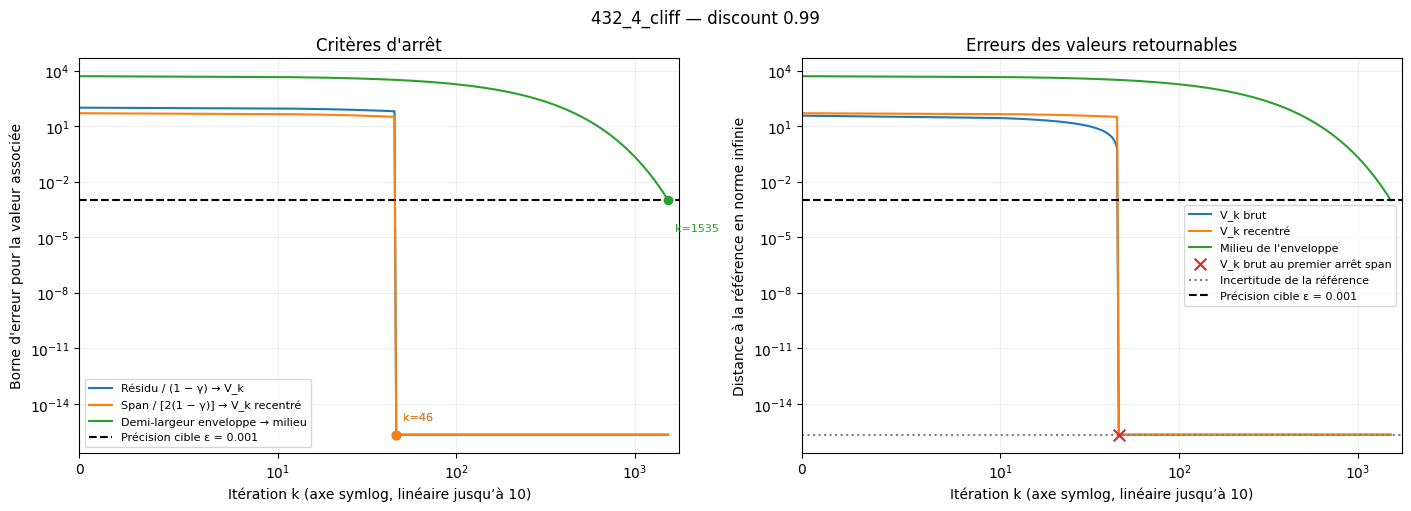

In [4]:
colors = {"residual": "tab:blue", "span": "tab:orange", "envelope": "tab:green"}
criterion_labels = {
    "residual": "Résidu / (1 − γ) → V_k",
    "span": "Span / [2(1 − γ)] → V_k recentré",
    "envelope": "Demi-largeur enveloppe → milieu",
}
error_labels = {
    "raw": ("V_k brut", "residual"),
    "shifted": ("V_k recentré", "span"),
    "midpoint": ("Milieu de l'enveloppe", "envelope"),
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
# Only the display clips zeros for a logarithmic axis; stored data stay unchanged.
plot_floor = np.finfo(float).eps
for name, series in bounds.items():
    axes[0].semilogy(
        iterations,
        np.maximum(series, plot_floor),
        color=colors[name],
        label=criterion_labels[name],
    )
    k = first_stops[name]
    axes[0].scatter(
        k,
        max(series[k], plot_floor),
        color=colors[name],
        zorder=3,
    )
    axes[0].annotate(
        f"k={k}",
        (k, max(series[k], plot_floor)),
        xytext=(5, -22 if name == "envelope" else 10),
        textcoords="offset points",
        color=colors[name],
        fontsize=8,
    )

for estimate, (label, criterion) in error_labels.items():
    axes[1].semilogy(
        iterations,
        np.maximum(errors[estimate], plot_floor),
        color=colors[criterion],
        label=label,
    )
axes[1].scatter(
    span_stop,
    max(errors["raw"][span_stop], plot_floor),
    color="tab:red",
    marker="x",
    s=70,
    zorder=4,
    label="V_k brut au premier arrêt span",
)
axes[1].axhline(
    max(reference_error_bound, plot_floor),
    color="0.5",
    linestyle=":",
    label="Incertitude de la référence",
)

for ax in axes:
    ax.axhline(
        PRECISION,
        color="black",
        linestyle="--",
        label=f"Précision cible ε = {PRECISION:g}",
    )
    ax.set_xscale("symlog", linthresh=10)
    ax.set_xlim(0, max(10, iterations[-1] * 1.15))
    ax.set_xlabel("Itération k (axe symlog, linéaire jusqu’à 10)")
    ax.grid(True, which="both", alpha=0.2)
    ax.legend(fontsize=8)

axes[0].set_title("Critères d'arrêt")
axes[0].set_ylabel("Borne d'erreur pour la valeur associée")
axes[1].set_title("Erreurs des valeurs retournables")
axes[1].set_ylabel("Distance à la référence en norme infinie")
fig.suptitle(f"{model.name} — discount {DISCOUNT}")
plt.show()